# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module — Research Assignment**

This notebook implements the **spectral modularity method** (leading eigenvector of the modularity matrix) from scratch on Zachary's Karate Club network, extends it to many communities by **recursive bisection**, visualizes the graph after every split, tracks four node-level network metrics across the splits, and discusses the results.

Only `numpy`, `matplotlib`, `pandas` and `networkx` are used. The eigen-decomposition uses `numpy.linalg.eigh`; the modularity matrix, the splitting rule, the recursion and the modularity score are all written by hand.

**Method reference.** The modularity objective, the modularity matrix $B$ and the spectral bipartition method follow M. E. J. Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582. Data: W. W. Zachary (1977), *An information flow model for conflict and fission in small groups*, J. Anthropological Research 33(4):452–473.

**Contents**
1. Data and ground truth
2. Modularity matrix and sanity checks
3. Spectral bisection and recursive bisection
4. Run: visualization after each split
5. Node metrics after each split
6. Evolution of the metrics
7. Discussion
8. References

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib import cm

np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| networkx", nx.__version__)

numpy 2.5.3 | networkx 3.7


## 1. Data and ground truth

`networkx` ships Zachary's network. Each node carries a `club` attribute recording which faction the member joined after the split: `'Mr. Hi'` (the instructor) or `'Officer'` (the administrator). We use it **only for evaluation**; the algorithm sees nothing but the graph structure.

In [2]:
G = nx.karate_club_graph()
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = sorted(G.nodes())                       # 0..33, matches matrix row/column order
# NOTE: recent NetworkX versions attach interaction-strength weights to this graph's edges.
# The handout uses the plain 0/1 adjacency matrix, so weights are explicitly ignored.
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted adjacency matrix, n x n
k = A.sum(axis=1)                               # degree vector
truth = {i: G.nodes[i]["club"] for i in nodes}  # ground truth, evaluation only

print(f"n = {n} nodes, m = {m} edges, sum of degrees = {int(k.sum())} (= 2m = {2*m})")
assert set(np.unique(A)) == {0.0, 1.0} and int(k.sum()) == 2 * m   # 0/1 entries, degrees sum to 2m
print("A symmetric:", np.allclose(A, A.T), "| connected:", nx.is_connected(G))
print("Ground-truth faction sizes:", pd.Series(truth).value_counts().to_dict())

# one fixed layout reused for EVERY drawing so that community changes are visible
pos = nx.spring_layout(G, seed=7)

n = 34 nodes, m = 78 edges, sum of degrees = 156 (= 2m = 156)
A symmetric: True | connected: True
Ground-truth faction sizes: {'Mr. Hi': 17, 'Officer': 17}


## 2. The modularity matrix

$$B = A - \frac{k k^\top}{2m}, \qquad B_{ij}=A_{ij}-\frac{k_ik_j}{2m}$$

The second term is the expected number of edges between $i$ and $j$ in the degree-preserving null model. For a $\pm1$ label vector $s$, the modularity is $Q=\frac{1}{4m}s^\top B s$.

Sanity checks from the handout: $B$ is real symmetric (Proposition 1), and $B\mathbf 1=0$ (Proposition 2), so the trivial partition has $Q=0$ (Corollary 1).

In [3]:
B = A - np.outer(k, k) / (2 * m)

print("B shape:", B.shape)
print("Proposition 1 – B symmetric:", np.allclose(B, B.T))
print("Proposition 2 – max |B·1|  :", np.abs(B @ np.ones(n)).max())
print("Corollary 1   – Q(all-ones):", (np.ones(n) @ B @ np.ones(n)) / (4 * m))

eigvals = np.linalg.eigvalsh(B)[::-1]
print("\nLargest 5 eigenvalues of B:", eigvals[:5])
print("Smallest eigenvalue of B  :", eigvals[-1])

B shape: (34, 34)
Proposition 1 – B symmetric: True
Proposition 2 – max |B·1|  : 8.881784197001252e-16
Corollary 1   – Q(all-ones): 8.718097469011646e-18

Largest 5 eigenvalues of B: [4.9771 3.0428 2.3202 1.4888 1.4594]
Smallest eigenvalue of B  : -5.592496342798062


## 3. Spectral bipartition and recursive bisection

**Bisection of a group $C$.**
1. Take the block $B^{(C)}$ of $B$ with rows/columns in $C$ (as specified in the handout).
2. Compute its leading eigenpair $(\lambda_1^{(C)},u_1^{(C)})$.
3. If $\lambda_1^{(C)}\le 0$, $C$ is indivisible (Theorem 3).
4. Otherwise set $s_i=+1$ if $(u_1)_i>0$, else $-1$, and split $C$ into $C^+$ and $C^-$.
   If all signs are equal the split is trivial, so $C$ is treated as indivisible.

**Recursion.** Start from all of $V$ and process groups in a queue. Each *successful* split is one **iteration**; iteration 0 is the unsplit graph. A group stops being processed once it is indivisible.

**Modularity of a partition** (used to track progress, computed from $B$ directly and cross-checked with NetworkX):
$$Q=\frac{1}{2m}\sum_{c}\sum_{i,j\in c}B_{ij}.$$

**Colours.** When a group splits, the first child (the one containing the smaller node id) keeps the parent's colour and the other child gets a new colour, so colours stay stable across iterations.

_Note on the generalized matrix._ In Newman (2006), the exact gain from splitting a subgroup uses $B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in g}B_{il}$, which differs from the plain block by a diagonal correction. The code below supports both via `generalized=`; the handout's plain block is the default and drives all main results. Section 4 compares the two.

In [4]:
def leading_eigenpair(M):
    # Leading (largest) eigenpair of a real symmetric matrix.
    w, V = np.linalg.eigh(M)          # eigenvalues in ascending order
    return w[-1], V[:, -1]


def restricted_B(C, B, generalized=False):
    # Block of B on the node set C; optionally with Newman's diagonal correction.
    idx = np.array(sorted(C))
    BC = B[np.ix_(idx, idx)].copy()
    if generalized:
        BC -= np.diag(BC.sum(axis=1))
    return idx, BC


def try_split(C, B, tol=1e-9, generalized=False):
    # Try to bisect group C. Returns ((C_plus, C_minus), lam) or (None, lam) if indivisible.
    idx, BC = restricted_B(C, B, generalized)
    lam, u = leading_eigenpair(BC)
    if lam <= tol:                                   # Theorem 3: no split helps
        return None, lam
    s = np.where(u > 0, 1, -1)                       # threshold back to +/-1
    if abs(s.sum()) == len(s):                       # one side empty -> trivial split
        return None, lam
    part_a = [int(i) for i, si in zip(idx, s) if si == 1]
    part_b = [int(i) for i, si in zip(idx, s) if si == -1]
    # deterministic order (eigenvector sign is arbitrary): group with smallest node id first
    return tuple(sorted((part_a, part_b), key=min)), lam


def modularity(partition, B, m):
    # Q = (1/2m) * sum over communities of the sum of B_ij inside each community.
    total = 0.0
    for C in partition:
        idx = np.array(sorted(C))
        total += B[np.ix_(idx, idx)].sum()
    return total / (2 * m)


def recursive_bisection(nodes, B, m, generalized=False, verbose=True):
    # Recursive spectral bisection. Returns (history, final_partition).
    # history[t] describes the state after iteration t (t = 0 is the unsplit graph).
    next_cid = 1
    pending = [(0, sorted(nodes))]                   # queue of (color_id, node list)
    final = []
    history = [dict(iteration=0, communities=[(0, sorted(nodes))], split=None,
                    lam=None, Q=modularity([sorted(nodes)], B, m))]
    it = 0
    while pending:
        cid, C = pending.pop(0)
        parts, lam = try_split(C, B, generalized=generalized)
        if parts is None:
            final.append((cid, C))
            if verbose:
                print(f"  group of size {len(C):2d}: leading eigenvalue = {lam:+.4f} -> indivisible, kept as community")
            continue
        it += 1
        (pa, pb) = parts
        new_cid = next_cid; next_cid += 1
        pending.append((cid, pa)); pending.append((new_cid, pb))
        communities = sorted(final + pending, key=lambda t: min(t[1]))
        Q = modularity([c for _, c in communities], B, m)
        history.append(dict(iteration=it, communities=communities,
                            split=(cid, len(C), len(pa), len(pb)), lam=lam, Q=Q))
        if verbose:
            print(f"Iteration {it}: split group of size {len(C)} (lambda1 = {lam:+.4f}) "
                  f"-> sizes {len(pa)} + {len(pb)}; communities = {len(communities)}; Q = {Q:.4f}")
    final = sorted(final, key=lambda t: min(t[1]))
    return history, final

## 4. Run on the Karate Club graph

First the log of every split (with the leading eigenvalue that justified it and the resulting modularity), then a check against NetworkX's own modularity function.

In [5]:
history, final = recursive_bisection(nodes, B, m)
final_partition = [C for _, C in final]
Q_final = modularity(final_partition, B, m)

print("\nFinal communities:")
for cid, C in final:
    print(f"  color {cid}: size {len(C):2d} -> {C}")
print(f"\nFinal modularity Q = {Q_final:.4f}")
print("NetworkX check     :", round(nx.community.modularity(G, [set(C) for C in final_partition], weight=None), 4))

Iteration 1: split group of size 34 (lambda1 = +4.9771) -> sizes 16 + 18; communities = 2; Q = 0.3715
Iteration 2: split group of size 16 (lambda1 = +2.9441) -> sizes 10 + 6; communities = 3; Q = 0.3898
Iteration 3: split group of size 18 (lambda1 = +2.5041) -> sizes 13 + 5; communities = 4; Q = 0.4081
  group of size 10: leading eigenvalue = +2.5712 -> indivisible, kept as community
Iteration 4: split group of size 6 (lambda1 = +2.1480) -> sizes 5 + 1; communities = 5; Q = 0.4094
  group of size 13: leading eigenvalue = +2.3563 -> indivisible, kept as community
  group of size  5: leading eigenvalue = +1.8759 -> indivisible, kept as community
  group of size  5: leading eigenvalue = +2.1470 -> indivisible, kept as community
  group of size  1: leading eigenvalue = -0.0064 -> indivisible, kept as community

Final communities:
  color 0: size 10 -> [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  color 2: size  5 -> [4, 5, 6, 10, 16]
  color 1: size 13 -> [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30,

In [6]:
# Table: one row per iteration
rows = []
for h in history:
    rows.append(dict(iteration=h["iteration"],
                     n_communities=len(h["communities"]),
                     sizes=sorted([len(c) for _, c in h["communities"]], reverse=True),
                     lambda1_of_split_group=None if h["lam"] is None else round(h["lam"], 4),
                     Q=round(h["Q"], 4)))
summary = pd.DataFrame(rows).set_index("iteration")
summary

,n_communities,sizes,lambda1_of_split_group,Q
iteration,,,,
0,1,[34],NaN,-0.0000
1,2,"[18, 16]",4.9771,0.3715
2,3,"[18, 10, 6]",2.9441,0.3898
3,4,"[13, 10, 6, 5]",2.5041,0.4081
4,5,"[13, 10, 5, 5, 1]",2.1480,0.4094


### Does the first split recover the real fission?

After iteration 1 we have two groups. We compare them with the actual factions (`Mr. Hi` vs `Officer`).

In [7]:
first = history[1]["communities"]
groupA, groupB = first[0][1], first[1][1]

def majority_label(C):
    return pd.Series([truth[i] for i in C]).value_counts().idxmax()

labA, labB = majority_label(groupA), majority_label(groupB)
print("Group with node 0 ->", labA, "| other group ->", labB)

confusion = pd.crosstab(pd.Series({i: ("group A" if i in groupA else "group B") for i in nodes}, name="detected"),
                        pd.Series(truth, name="actual"))
print(confusion, "\n")

wrong = [i for i in nodes if (truth[i] == labA) != (i in groupA)]
print(f"Correctly placed: {n - len(wrong)}/{n}  ({(n-len(wrong))/n:.1%})")
print("Misplaced nodes:", wrong, "->", [(i, truth[i]) for i in wrong])

Group with node 0 -> Mr. Hi | other group -> Officer
actual    Mr. Hi  Officer
detected                 
group A       16        0
group B        1       17 

Correctly placed: 33/34  (97.1%)
Misplaced nodes: [8] -> [(8, 'Mr. Hi')]


### Visualization after each split
Same fixed layout every time; one colour per community; nodes labelled by ID. Iteration 0 is shown for reference next to the ground-truth factions.

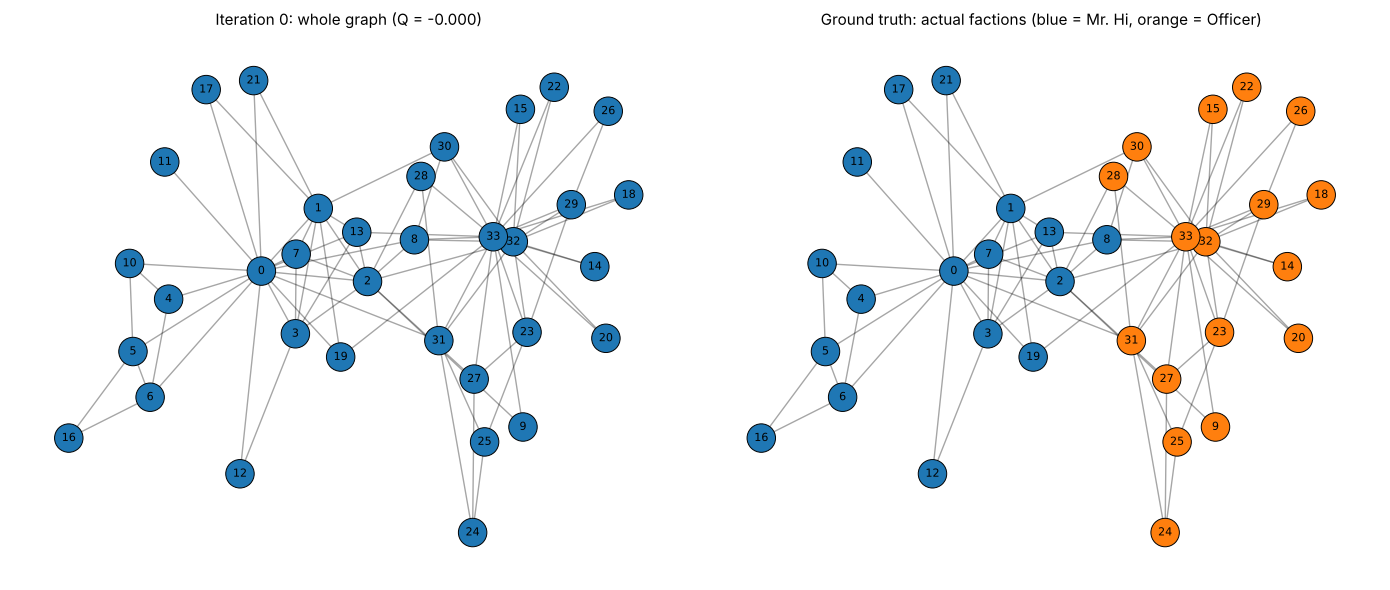

In [8]:
palette = plt.get_cmap("tab10")

def draw_partition(ax, communities, title):
    color_of = {}
    for cid, C in communities:
        for i in C:
            color_of[i] = palette(cid % 10)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=1.0)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[color_of[i] for i in nodes],
                           node_size=420, edgecolors="black", linewidths=0.7)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

# Reference: iteration 0 and ground truth
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw_partition(axes[0], history[0]["communities"], f"Iteration 0: whole graph (Q = {history[0]['Q']:.3f})")
truth_comm = [(0, [i for i in nodes if truth[i] == "Mr. Hi"]), (1, [i for i in nodes if truth[i] == "Officer"])]
draw_partition(axes[1], truth_comm, "Ground truth: actual factions (blue = Mr. Hi, orange = Officer)")
plt.tight_layout(); plt.show()

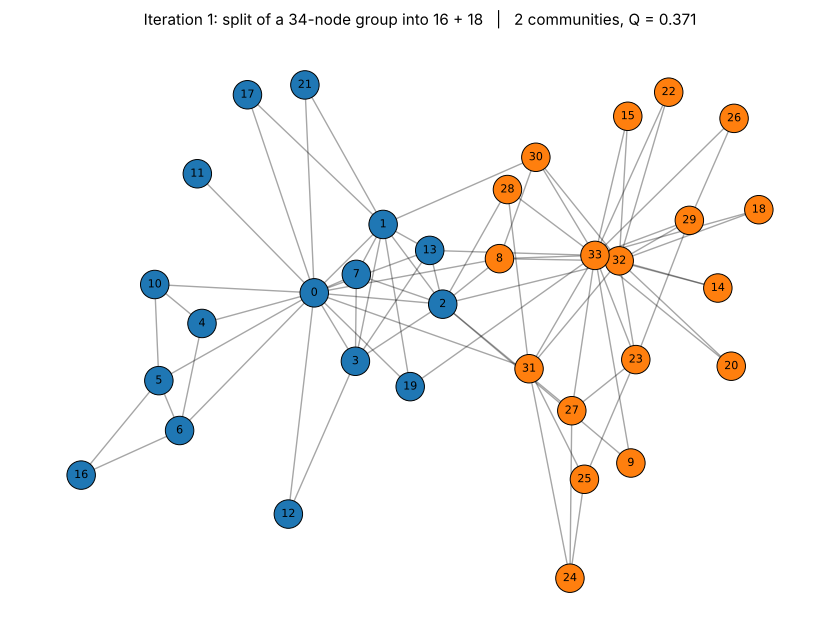

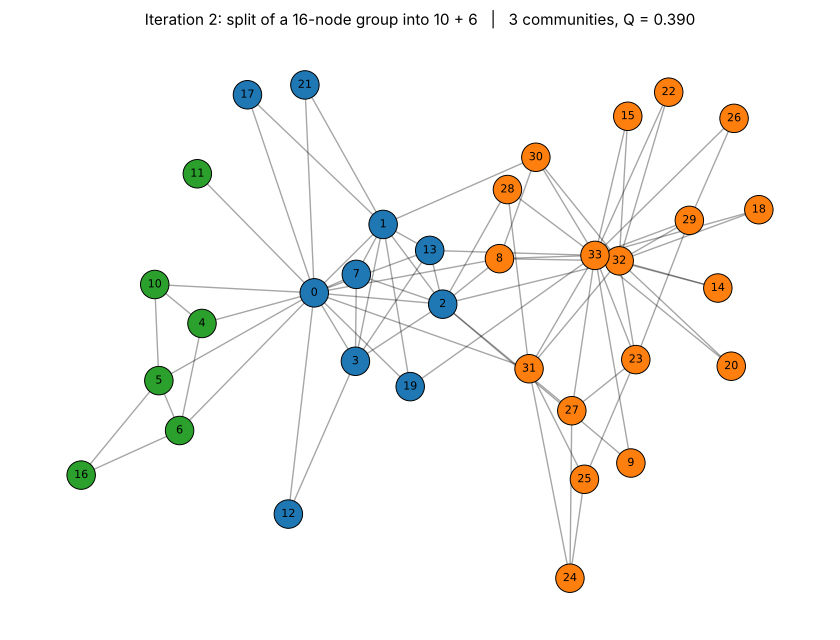

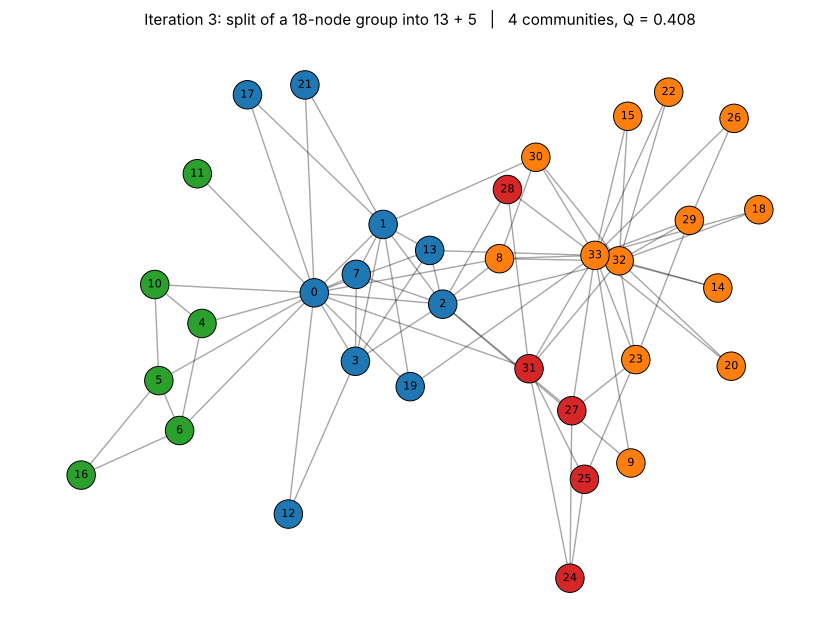

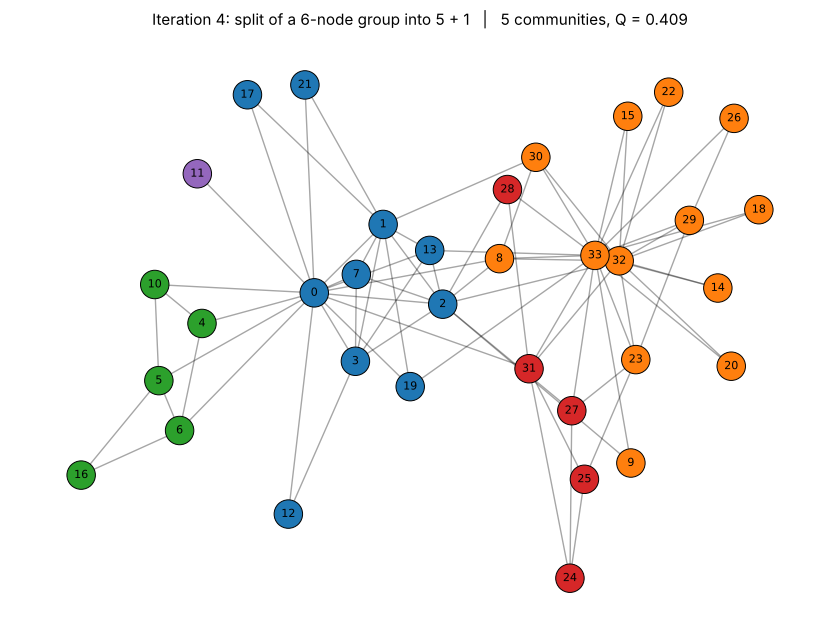

In [9]:
for h in history[1:]:
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    cid, size, sa, sb = h["split"]
    draw_partition(ax, h["communities"],
                   f"Iteration {h['iteration']}: split of a {size}-node group into {sa} + {sb}   "
                   f"|   {len(h['communities'])} communities, Q = {h['Q']:.3f}")
    plt.tight_layout(); plt.show()

## 5. Node metrics after each split

The handout asks for degree, betweenness, closeness and clustering after each split using NetworkX. On the *whole* graph these numbers would never change (splitting is just a relabelling), so the metrics are computed **inside each node's current community**: for every iteration, each community $C$ is turned into the induced subgraph `G.subgraph(C)` and the four NetworkX functions are run on it.

Iteration 0 is the whole graph, so it gives the ordinary global values. Values from later iterations describe a node's standing *within its own community*. Note that the normalisations depend on community size ($n-1$), so values from communities of different sizes are comparable only loosely.

In [10]:
METRICS = {
    "degree centrality":      nx.degree_centrality,
    "betweenness centrality": nx.betweenness_centrality,
    "closeness centrality":   nx.closeness_centrality,
    "clustering coefficient": nx.clustering,
}

def community_metrics(G, communities):
    # Compute each metric inside every community's induced subgraph.
    out = {name: {} for name in METRICS}
    for _, C in communities:
        H = G.subgraph(C)
        for name, fn in METRICS.items():
            out[name].update(fn(H))
    return out

# metric_history[metric][iteration] = {node: value}   (dictionary keyed by iteration number)
metric_history = {name: {} for name in METRICS}
for h in history:
    res = community_metrics(G, h["communities"])
    for name in METRICS:
        metric_history[name][h["iteration"]] = res[name]

iters = sorted(history_i["iteration"] for history_i in history)
tables = {name: pd.DataFrame(metric_history[name]).loc[nodes] for name in METRICS}   # rows = nodes, cols = iterations
for name, df in tables.items():
    df.index.name = "node"; df.columns.name = "iteration"

print("Stored", len(METRICS), "metrics for iterations", iters)
tables["degree centrality"].round(3).head(10)

Stored 4 metrics for iterations [0, 1, 2, 3, 4]


iteration,0,1,2,3,4
node,,,,,
0,0.485,0.933,1.000,1.000,1.000
1,0.273,0.533,0.889,0.889,0.889
2,0.303,0.333,0.556,0.556,0.556
3,0.182,0.400,0.667,0.667,0.667
4,0.091,0.200,0.400,0.400,0.500
5,0.121,0.267,0.600,0.600,0.750
6,0.121,0.267,0.600,0.600,0.750
7,0.121,0.267,0.444,0.444,0.444
8,0.152,0.176,0.176,0.250,0.250


In [11]:
# Global sanity check: iteration 0 must equal the plain NetworkX values on the full graph
for name, fn in METRICS.items():
    ref = pd.Series(fn(G)).loc[nodes]
    assert np.allclose(tables[name][0].values, ref.values), name
print("Iteration-0 metrics match NetworkX on the full graph for all four metrics.")

Iteration-0 metrics match NetworkX on the full graph for all four metrics.


## 6. Evolution of the metrics across iterations
For each metric: **left**, one line per node (the five highest-degree nodes are coloured and labelled, the rest are grey); **right**, a heatmap of every node across all iterations.

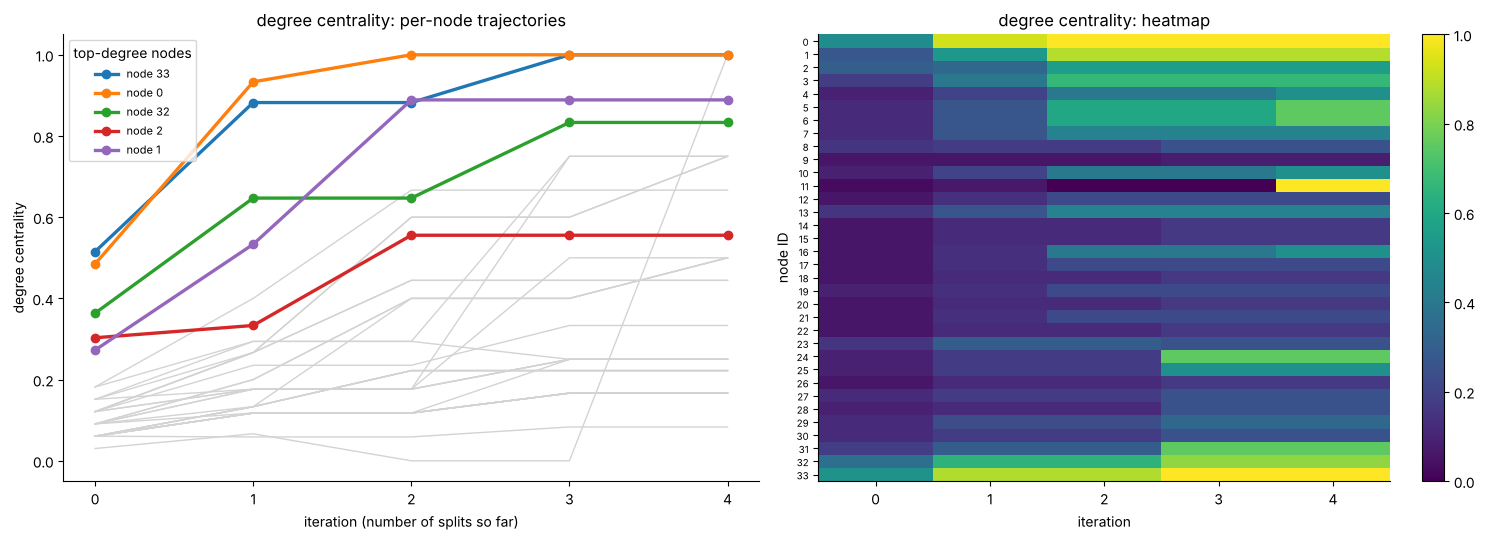

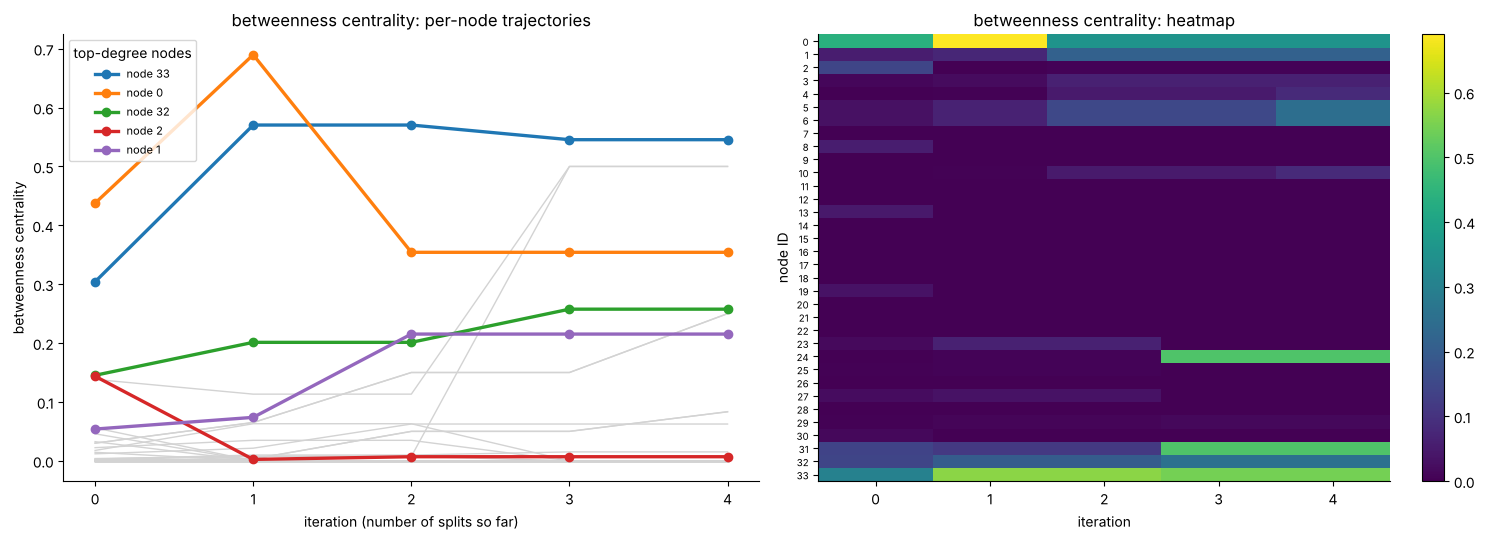

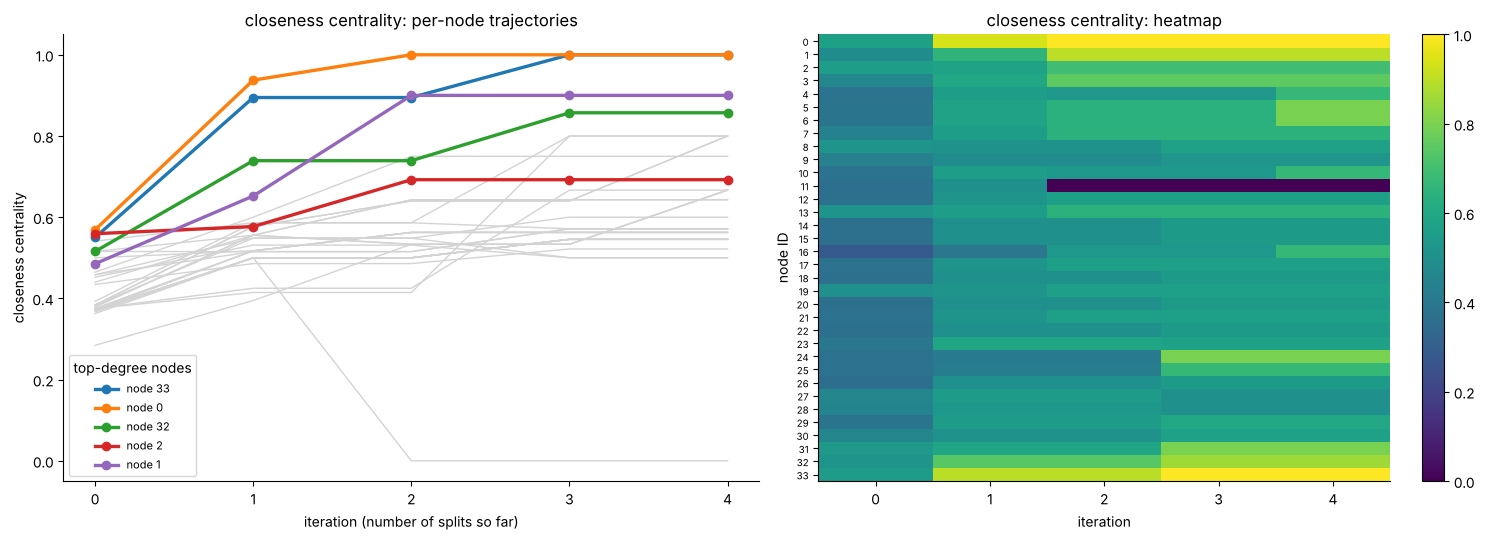

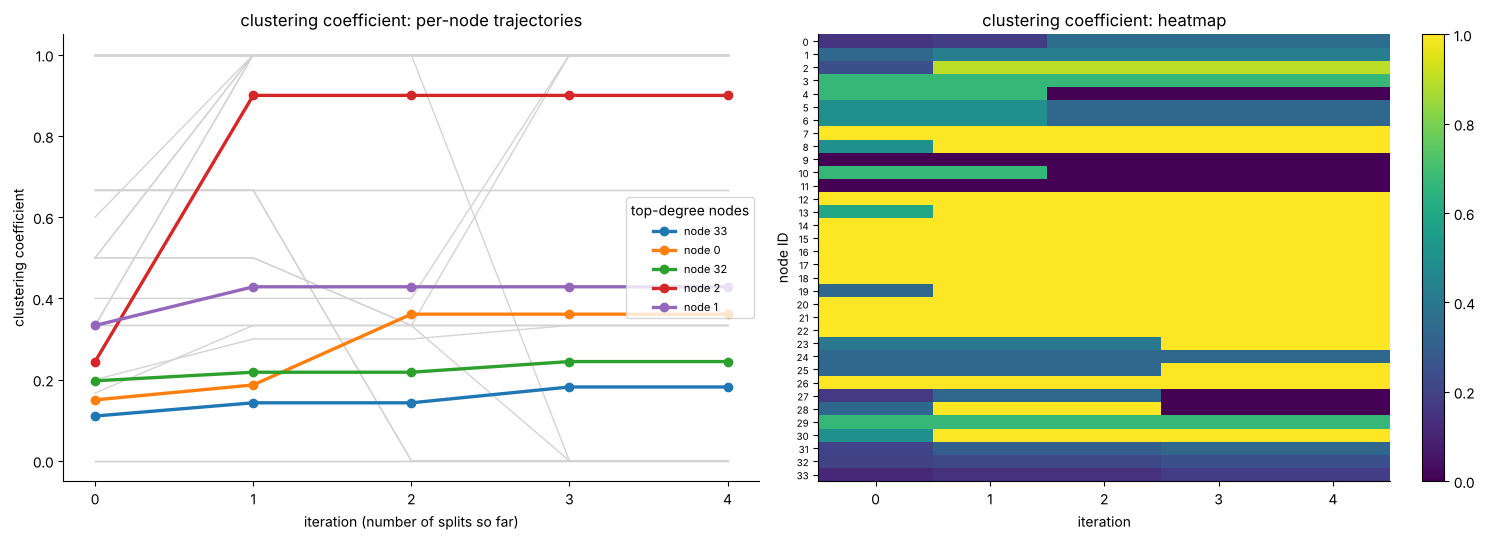

In [12]:
top_nodes = sorted(nodes, key=lambda i: -k[i])[:5]           # five highest-degree nodes
line_colors = {nd: palette(j) for j, nd in enumerate(top_nodes)}

for name, df in tables.items():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
    for nd in nodes:
        if nd not in top_nodes:
            ax1.plot(df.columns, df.loc[nd], color="lightgray", lw=1, zorder=1)
    for nd in top_nodes:
        ax1.plot(df.columns, df.loc[nd], color=line_colors[nd], lw=2.4, marker="o", label=f"node {nd}", zorder=3)
    ax1.set_xticks(list(df.columns)); ax1.set_xlabel("iteration (number of splits so far)")
    ax1.set_ylabel(name); ax1.set_title(f"{name}: per-node trajectories"); ax1.legend(title="top-degree nodes", fontsize=8)

    im = ax2.imshow(df.values, aspect="auto", cmap="viridis")
    ax2.set_xticks(range(len(df.columns))); ax2.set_xticklabels(df.columns)
    ax2.set_yticks(range(n)); ax2.set_yticklabels(nodes, fontsize=7)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node ID"); ax2.set_title(f"{name}: heatmap")
    fig.colorbar(im, ax=ax2, fraction=0.046)
    plt.tight_layout(); plt.show()

### Who stays central? Rankings across iterations
For each metric and iteration, take the top-5 nodes (ranking all nodes by their within-community value). Nodes that appear in the top-5 in **every** iteration are the consistently central ones.

In [13]:
TOPK = 5
ranking_rows = []
for name, df in tables.items():
    tops = {it: list(df[it].sort_values(ascending=False, kind="mergesort").index[:TOPK]) for it in df.columns}
    always = set.intersection(*[set(t) for t in tops.values()])
    ranking_rows.append({"metric": name,
                         **{f"top-{TOPK} @ it {it}": tops[it] for it in df.columns},
                         "in top-5 at every iteration": sorted(always)})
pd.set_option("display.max_colwidth", 80, "display.width", 250)
pd.DataFrame(ranking_rows).set_index("metric").T

metric,degree centrality,betweenness centrality,closeness centrality,clustering coefficient
top-5 @ it 0,"[33, 0, 32, 2, 1]","[0, 33, 32, 2, 31]","[0, 2, 33, 31, 8]","[7, 12, 14, 15, 16]"
top-5 @ it 1,"[0, 33, 32, 1, 3]","[0, 33, 32, 31, 1]","[0, 33, 32, 1, 3]","[7, 8, 12, 13, 14]"
top-5 @ it 2,"[0, 1, 33, 3, 32]","[33, 0, 1, 32, 5]","[0, 1, 33, 3, 32]","[7, 8, 12, 13, 14]"
top-5 @ it 3,"[0, 33, 1, 32, 24]","[33, 24, 31, 0, 32]","[0, 33, 1, 32, 24]","[7, 8, 12, 13, 14]"
top-5 @ it 4,"[0, 11, 33, 1, 32]","[33, 24, 31, 0, 32]","[0, 33, 1, 32, 5]","[7, 8, 12, 13, 14]"
in top-5 at every iteration,"[0, 1, 32, 33]","[0, 32, 33]","[0, 33]","[7, 12, 14]"


In [14]:
# Average rank over iterations (1 = most central), lower is more consistently central
mean_rank = pd.DataFrame({name: df.rank(ascending=False, method="average").mean(axis=1)
                          for name, df in tables.items()})
mean_rank["overall"] = mean_rank.mean(axis=1)
mean_rank["community (final)"] = {i: next(cid for cid, C in final if i in C) for i in nodes}
mean_rank["faction"] = pd.Series(truth)
mean_rank.sort_values("overall").head(8).round(2)

,degree centrality,betweenness centrality,closeness centrality,clustering coefficient,overall,community (final),faction
node,,,,,,,
0,1.5,2.4,1.2,25.6,7.68,0,Mr. Hi
33,1.9,1.4,2.2,30.0,8.88,1,Officer
1,3.6,5.8,4.2,22.0,8.90,0,Mr. Hi
32,4.0,4.0,4.4,28.4,10.20,1,Officer
3,6.5,10.8,7.0,18.1,10.60,0,Mr. Hi
31,8.3,4.2,6.8,26.8,11.52,3,Officer
2,7.8,12.4,7.0,19.4,11.65,0,Mr. Hi
5,9.3,7.2,11.1,23.0,12.65,2,Mr. Hi


In [15]:
# How much does the metric of a node change once communities are formed? (iteration 0 -> last iteration)
last = max(iters)
change = pd.DataFrame({name: tables[name][last] - tables[name][0] for name in METRICS})
print("Mean change from iteration 0 to the last iteration, per metric:")
print(change.mean().round(3).to_string())
print("\nLargest increases in closeness (nodes that become more 'central' inside a small community):")
print(change["closeness centrality"].sort_values(ascending=False).head(5).round(3).to_string())
print("\nLargest drops in degree centrality (hubs of the whole graph, relative to community size):")
print(change["degree centrality"].sort_values().head(5).round(3).to_string())

Mean change from iteration 0 to the last iteration, per metric:
degree centrality         0.314
betweenness centrality    0.048
closeness centrality      0.212
clustering coefficient    0.070

Largest increases in closeness (nodes that become more 'central' inside a small community):
node
33    0.450
0     0.431
24    0.425
5     0.416
6     0.416

Largest drops in degree centrality (hubs of the whole graph, relative to community size):
node
9     0.023
8     0.098
23    0.098
15    0.106
22    0.106


### Extra check: Newman's generalized $B^{(g)}$ versus the handout's plain block

The handout restricts $B$ to the block $B^{(C)}$. Newman's paper adds a diagonal correction so that the matrix measures the *exact* change in total modularity from splitting a group. Here is what that variant would give on this graph (it does not drive any result above).

In [16]:
print("Handout rule (plain block):")
_, fin_plain = recursive_bisection(nodes, B, m, generalized=False, verbose=False)
print("  communities:", len(fin_plain), "| Q =", round(modularity([C for _, C in fin_plain], B, m), 4),
      "| sizes:", sorted([len(C) for _, C in fin_plain], reverse=True))

print("Newman's generalized B^(g):")
hist_g, fin_g = recursive_bisection(nodes, B, m, generalized=True, verbose=True)
print("  communities:", len(fin_g), "| Q =", round(modularity([C for _, C in fin_g], B, m), 4),
      "| sizes:", sorted([len(C) for _, C in fin_g], reverse=True))
print("Same final partition:", sorted(map(tuple, (C for _, C in fin_plain))) == sorted(map(tuple, (C for _, C in fin_g))))

Handout rule (plain block):
  communities: 5 | Q = 0.4094 | sizes: [13, 10, 5, 5, 1]
Newman's generalized B^(g):
Iteration 1: split group of size 34 (lambda1 = +4.9771) -> sizes 16 + 18; communities = 2; Q = 0.3715
Iteration 2: split group of size 16 (lambda1 = +1.1785) -> sizes 7 + 9; communities = 3; Q = 0.3727
Iteration 3: split group of size 18 (lambda1 = +0.8594) -> sizes 12 + 6; communities = 4; Q = 0.3934
  group of size  7: leading eigenvalue = -0.0000 -> indivisible, kept as community
Iteration 4: split group of size 9 (lambda1 = +0.0602) -> sizes 4 + 5; communities = 5; Q = 0.3776
  group of size 12: leading eigenvalue = -0.0000 -> indivisible, kept as community
  group of size  6: leading eigenvalue = +0.0000 -> indivisible, kept as community
  group of size  4: leading eigenvalue = +0.0000 -> indivisible, kept as community
  group of size  5: leading eigenvalue = -0.0000 -> indivisible, kept as community
  communities: 5 | Q = 0.3776 | sizes: [12, 7, 6, 5, 4]
Same final par

## 7. Discussion

**Method result.** Applying Newman's (2006) leading-eigenvector method to the unweighted Karate Club graph gives a first split into groups of 16 and 18 (λ₁ ≈ 4.98, Q ≈ 0.372). Compared with the real fission this places 33 of 34 members correctly; only node 8, a Mr. Hi member with edges into both camps, lands on the Officer side. Recursive bisection then continues while the leading eigenvalue of the restricted block is positive and stops at **5 communities with Q ≈ 0.409** (matching `nx.community.modularity`). Later splits add little (0.372 → 0.390 → 0.408 → 0.409), so the main structure is the two-faction split, with the extra communities being finer sub-groups inside each faction. The last split peels off node 11, a degree-1 node whose only neighbour (node 0) sits in another group; this is a weak spot of the plain-block rule and sign thresholding rather than a meaningful community.

**Which nodes stay central across splits** (metrics measured inside each node's current community; iteration 0 is the whole graph):

- **Nodes 0 and 33** (the two faction leaders, Mr. Hi and the Officer) are the most persistent. Both are in the top 5 for closeness at every iteration, and both, together with node 32, for betweenness. For degree centrality the always-top-5 set is {0, 1, 32, 33}. Averaged over the four metrics' rankings, node 0 ranks best, followed by 33, 1, 32 and 3 (see the mean-rank table).
- **Clustering coefficient behaves differently.** Its leaders (nodes 7, 12, 14 in the top 5 at every iteration) are low-degree members of tight cliques, not hubs. Node 2, for instance, has modest whole-graph clustering (0.24) that jumps to 0.90 once it is inside the dense Mr. Hi sub-group.

**How community structure shapes the metrics.**

1. *Hubs separate into separate communities.* Nodes 0 and 33 fall into different groups at the very first split, and each becomes the centre of its own community: closeness for node 0 rises from 0.57 to 1.0, and node 33's from 0.55 to 1.0, because every other member is now close to them.
2. *Betweenness measures brokerage, which only exists across communities.* Node 2 is a bridge in the whole graph (betweenness 0.144) but is not needed for paths inside its own group (0.007 after splitting). Node 8, a boundary node, drops from 0.056 to 0. In contrast, node 31 jumps from 0.138 to 0.500 when it becomes the hub of its small 5-node group.
3. *Normalisation inflates values in small groups.* Degree and closeness are divided by (size − 1), so averages increase as communities shrink (mean change from iteration 0 to the last iteration: degree +0.31, closeness +0.21, betweenness +0.05, clustering +0.07). Comparisons across communities of different sizes should therefore be read as "importance within its own group", not as a global ranking.
4. *Disconnected members get zero scores.* When a node's neighbours sit in other groups, its induced subgraph shows no connections (node 11: closeness 0 from iteration 2 onwards).

**Caveats.**
- The handout restricts B to a plain block and stops when λ₁ ≤ 0. A positive λ₁ does not guarantee that the sign-rounded split improves Q; the exact gain uses Newman's generalized matrix with a diagonal correction. The extra check in Section 6 shows this variant ends on a different 5-community partition with lower Q (≈ 0.378), because it also splits groups on very small positive eigenvalues, so neither rule is a strict optimizer of Q.
- Karate Club has only 34 nodes, so the metric trajectories are sensitive to single-node changes, and results depend on this specific graph.


## 8. References

1. M. E. J. Newman, *Modularity and community structure in networks*, Proceedings of the National Academy of Sciences 103(23):8577–8582, 2006.
2. W. W. Zachary, *An information flow model for conflict and fission in small groups*, Journal of Anthropological Research 33(4):452–473, 1977.
3. A. A. Hagberg, D. A. Schult, P. J. Swart, *Exploring network structure, dynamics, and function using NetworkX*, Proceedings of the 7th Python in Science Conference (SciPy 2008).
4. DSC212 Graph Theory Module, Research Assignment handout: *Modularity on the Karate Club Graph*.